# 01 EDA: Data Quality
- CMPE 188 Group 13
- Dataset: Pima Indians Diabetes
- Data Engineer - Mita Yang

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 24
DATA_URL = "https://raw.githubusercontent.com/tanay2405/CMPE188_Project_Group13/main/pima_diabetes_train.csv"

df = pd.read_csv(DATA_URL)
print(df.shape)
df.head()

(652, 9)


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,age,outcome
0,8,85,55,20,0,24.4,0.136,42,tested_negative
1,2,114,68,22,0,28.7,0.092,25,tested_negative
2,10,101,76,48,180,32.9,0.171,63,tested_negative
3,4,91,70,32,88,33.1,0.446,22,tested_negative
4,0,119,66,27,0,38.8,0.259,22,tested_negative


## 2. Dataset Structure
The dataset contains patient health measurements used to predict diabetes outcome. We first inspect the number of rows and columns, data types, summary statistics, duplicates, and standard missing values. This helps identify basic data-quality issues before preprocessing.

In [ ]:
print("Shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

df.describe()

Shape: (652, 9)

Data types:
pregnancies            int64
glucose                int64
blood_pressure         int64
skin_thickness         int64
insulin                int64
bmi                  float64
diabetes_pedigree    float64
age                    int64
outcome               object
dtype: object

Missing values:
pregnancies          0
glucose              0
blood_pressure       0
skin_thickness       0
insulin              0
bmi                  0
diabetes_pedigree    0
age                  0
outcome              0
dtype: int64

Duplicate rows: 0


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,age
count,652.000000,652.000000,652.000000,652.000000,652.000000,652.000000,652.000000,652.000000
mean,3.857362,120.884969,69.130368,20.415644,77.415644,32.127454,0.468452,33.254601
std,3.429728,31.933792,19.631862,16.143289,112.020409,7.833709,0.333026,11.756865
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000
25%,1.000000,99.000000,63.500000,0.000000,0.000000,27.500000,0.238000,24.000000
50%,3.000000,116.500000,72.000000,23.000000,20.000000,32.200000,0.363000,29.000000
75%,6.000000,140.250000,80.000000,32.000000,126.000000,36.600000,0.624500,41.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000


## 3. Target Label
The target column is outcome, which contains two categories: tested_positive and tested_negative.

In [ ]:
print(df["outcome"].value_counts())
print("\nUnique target values:", df["outcome"].unique())

outcome
tested_negative    424
tested_positive    228
Name: count, dtype: int64

Unique target values: ['tested_negative' 'tested_positive']


## 4. Hidden Missing Values
Although the dataset contains no standard NaN values, some medical measurements contain zeros that are not physiologically realistic. For glucose, blood pressure, skin thickness, insulin, and BMI, a zero likely represents a measurement that was not recorded rather than a true value.

We count these zeros before deciding how they should be handled during preprocessing.

In [ ]:
zero_columns = [
    "glucose",
    "blood_pressure",
    "skin_thickness",
    "insulin",
    "bmi"
]

zero_counts = (df[zero_columns] == 0).sum()

zero_percent = ((df[zero_columns] == 0).mean() * 100).round(2)

hidden_missing = pd.DataFrame({
    "Zero Count": zero_counts,
    "Percent of Data": zero_percent
})

hidden_missing

,Zero Count,Percent of Data
glucose,4,0.61
blood_pressure,31,4.75
skin_thickness,198,30.37
insulin,322,49.39
bmi,9,1.38


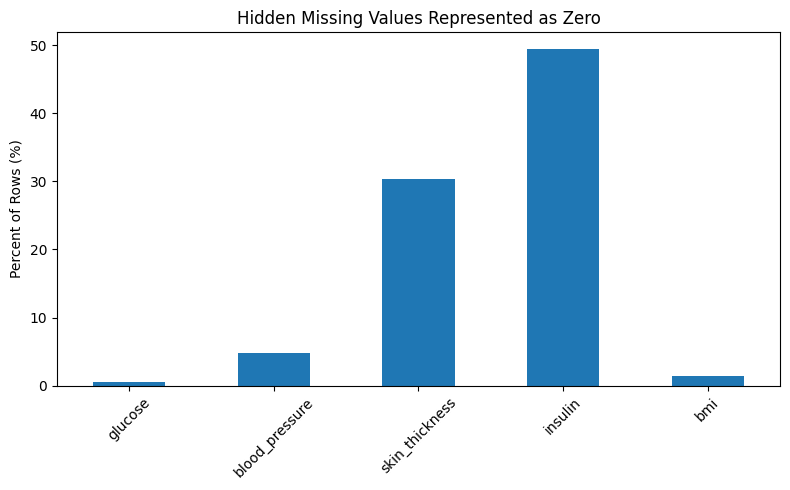

In [ ]:
hidden_missing["Percent of Data"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.ylabel("Percent of Rows (%)")
plt.title("Hidden Missing Values Represented as Zero")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Patterns in the Missing Values
Hidden missing values may not occur independently. For example, patients with missing insulin measurements may also be missing skin-thickness measurements. We examine how often these missing-value indicators appear together.

In [ ]:
missing_flags = df[zero_columns].eq(0)

missing_flags.corr()

,glucose,blood_pressure,skin_thickness,insulin,bmi
glucose,1.000000,-0.017554,-0.051886,0.040251,-0.009295
blood_pressure,-0.017554,1.000000,0.306976,0.226185,0.405973
skin_thickness,-0.051886,0.306976,1.000000,0.668550,0.150561
insulin,0.040251,0.226185,0.668550,1.000000,0.093476
bmi,-0.009295,0.405973,0.150561,0.093476,1.000000


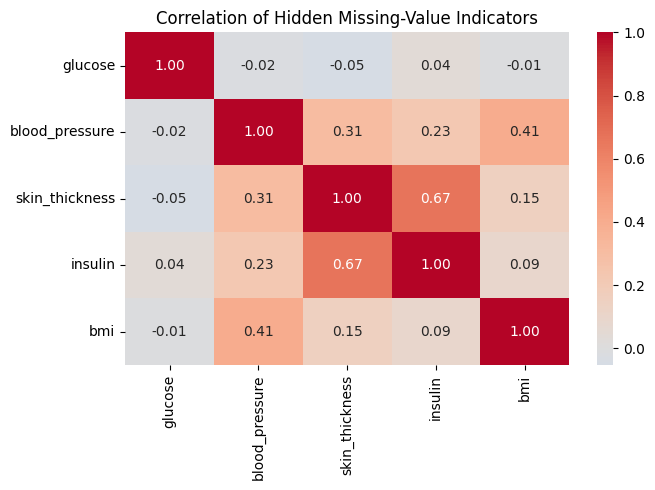

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    missing_flags.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation of Hidden Missing-Value Indicators")
plt.tight_layout()
plt.show()

## 6. Outliers

In [ ]:
df_clean_view = df.copy()

df_clean_view[zero_columns] = (
    df_clean_view[zero_columns]
    .replace(0, np.nan)
)

After treating medically invalid zeros as missing values, we examine numeric features for unusually high or low observations. Outliers are not automatically removed because extreme medical measurements may represent legitimate patients. Instead, they are identified so their effect can be considered during preprocessing and modeling.

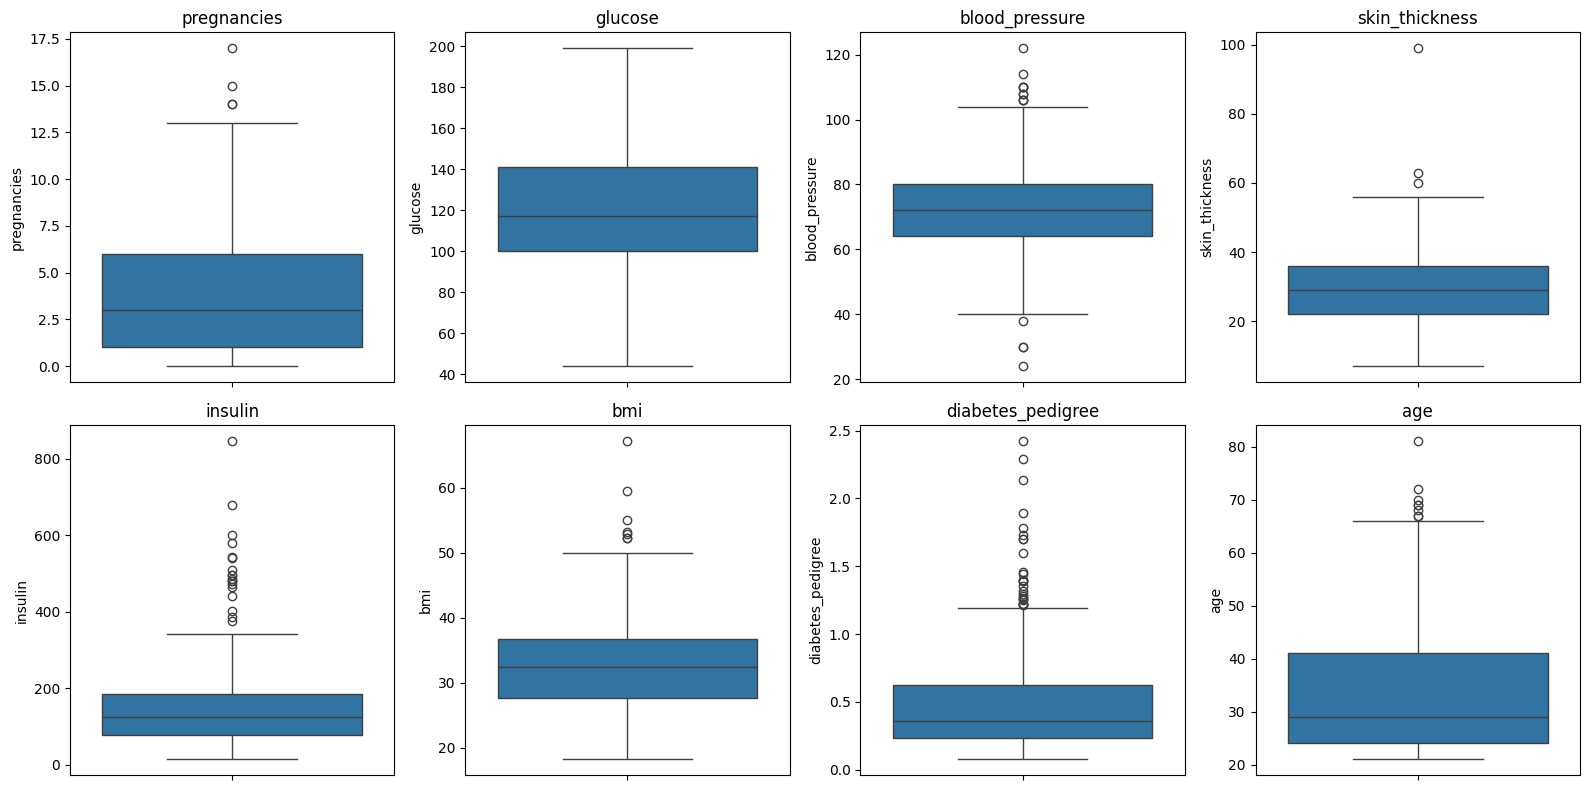

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, col in zip(axes.ravel(), numeric_cols):
    sns.boxplot(y=df_clean_view[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

## 7. Distributions and Skew
We examine the distributions of the numeric features after converting invalid zeros to missing values. Skewed variables may benefit from transformations or robust scaling during preprocessing. Histograms also help identify unusual ranges and long-tailed distributions.

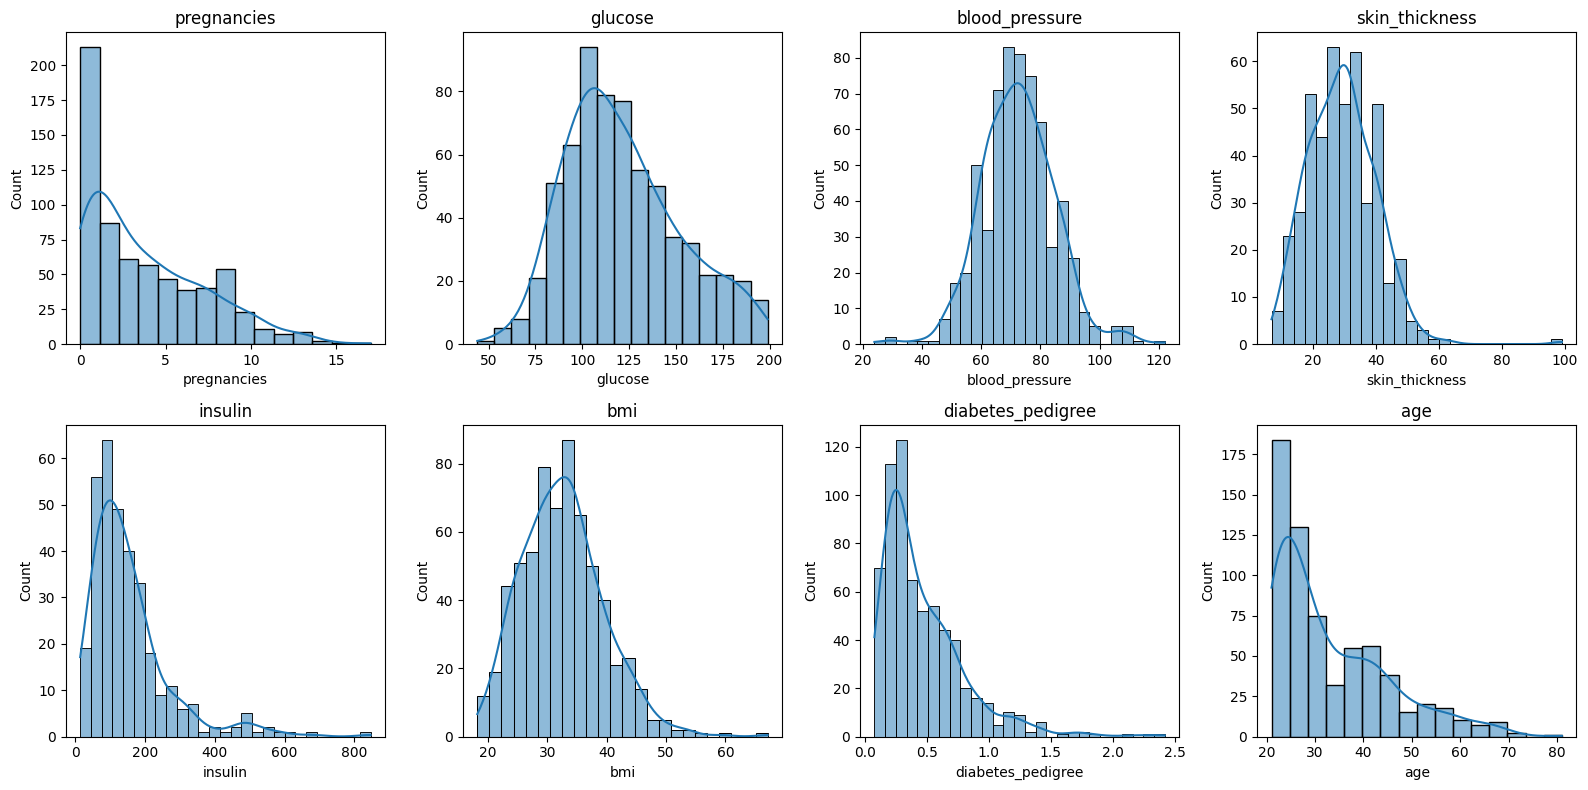

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, col in zip(axes.ravel(), numeric_cols):
    sns.histplot(
        df_clean_view[col],
        kde=True,
        ax=ax
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [ ]:
skewness = (
    df_clean_view[numeric_cols]
    .skew()
    .sort_values(ascending=False)
)

skewness

,0
insulin,2.240314
diabetes_pedigree,1.880606
age,1.152899
pregnancies,0.908811
skin_thickness,0.793634
bmi,0.611450
glucose,0.508636
blood_pressure,0.160606


## 8. Data Quality Summary

- The dataset contains 652 rows and 9 columns.
- No standard missing values or duplicate rows were found.
- Several medical features contain zero values that likely represent missing measurements.
- Insulin and skin thickness contain the largest amounts of hidden missing data.
- Several numeric features contain possible outliers, but these should not automatically be removed because they may represent valid patient measurements.
- Some features are right-skewed and may require scaling, transformation, or other preprocessing before model training.